In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10
from sklearn.metrics import (confusion_matrix, classification_report,
                              precision_score, recall_score, f1_score, accuracy_score)
import seaborn as sns

print("TensorFlow version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

np.random.seed(42)
tf.random.set_seed(42)


TensorFlow version: 2.20.0
GPU Available: []


In [2]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

print("Training data shape :", x_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing data shape  :", x_test.shape)
print("Testing labels shape :", y_test.shape)
print("Number of classes   :", len(class_names))


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2824s 17us/step
Training data shape : (50000, 32, 32, 3)
Training labels shape: (50000, 1)
Testing data shape  : (10000, 32, 32, 3)
Testing labels shape : (10000, 1)
Number of classes   : 10


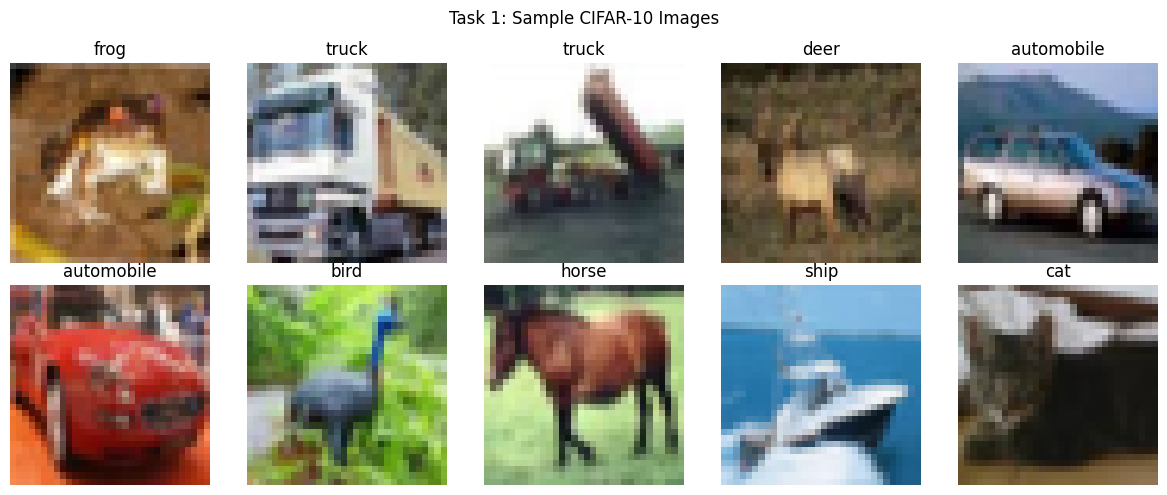

In [3]:
# Display ten sample images
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.axis('off')
plt.suptitle("Task 1: Sample CIFAR-10 Images")
plt.tight_layout()
plt.savefig("sample_images.png", dpi=150)
plt.show()


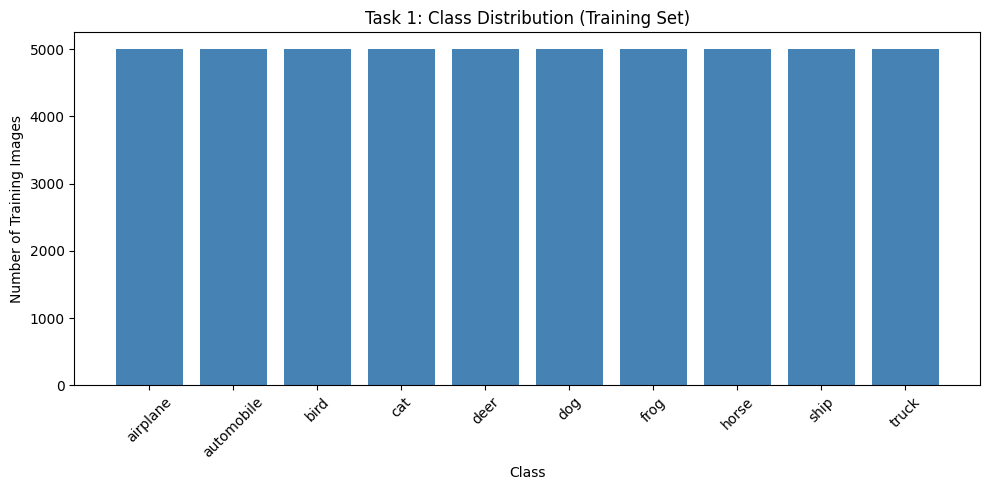

In [4]:
# Class distribution plot
unique, counts = np.unique(y_train, return_counts=True)
plt.figure(figsize=(10, 5))
plt.bar([class_names[i] for i in unique], counts, color='steelblue')
plt.xlabel("Class")
plt.ylabel("Number of Training Images")
plt.title("Task 1: Class Distribution (Training Set)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150)
plt.show()


In [6]:
x_train_norm = x_train.astype('float32') / 255.0
x_test_norm = x_test.astype('float32') / 255.0

y_train_cat = tf.keras.utils.to_categorical(y_train, 10)
y_test_cat = tf.keras.utils.to_categorical(y_test, 10)


In [7]:
def build_single_conv_model(kernel_size, input_shape=(32, 32, 3), filters=8):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(filters, kernel_size, activation='relu', padding='valid')
    ])
    return model

sample_img = x_train_norm[0:1]  # shape (1, 32, 32, 3)

kernel_sizes = [3, 5, 7]
print(f"{'Kernel Size':<15}{'Output Feature Map Shape':<30}")
print("-" * 45)
for k in kernel_sizes:
    model_k = build_single_conv_model((k, k))
    out = model_k.predict(sample_img, verbose=0)
    print(f"{f'{k}x{k}':<15}{str(out.shape):<30}")


Kernel Size    Output Feature Map Shape      
---------------------------------------------
3x3            (1, 30, 30, 8)                
5x5            (1, 28, 28, 8)                
7x7            (1, 26, 26, 8)                


In [8]:
def output_size(n, f, p, s):
    return (n - f + 2 * p) // s + 1

configs = [
    {"stride": 1, "padding": "valid"},
    {"stride": 2, "padding": "valid"},
    {"stride": 1, "padding": "same"},
    {"stride": 2, "padding": "same"},
]

print(f"{'Stride':<10}{'Padding':<10}{'Output Shape (Keras)':<25}{'Manual Calc (F=3)'}")
print("-" * 65)
for cfg in configs:
    model_h = models.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(8, 3, strides=cfg["stride"], padding=cfg["padding"], activation='relu')
    ])
    out = model_h.predict(sample_img, verbose=0)

    # manual calculation (padding formula: 'same' -> p chosen so output = ceil(N/S))
    if cfg["padding"] == "valid":
        manual = output_size(32, 3, 0, cfg["stride"])
    else:
        # 'same' padding output size = ceil(N / S)
        manual = int(np.ceil(32 / cfg["stride"]))

    print(f"{cfg['stride']:<10}{cfg['padding']:<10}{str(out.shape):<25}{manual}")


Stride    Padding   Output Shape (Keras)     Manual Calc (F=3)
-----------------------------------------------------------------
1         valid     (1, 30, 30, 8)           30


2         valid     (1, 15, 15, 8)           15
1         same      (1, 32, 32, 8)           32
2         same      (1, 16, 16, 8)           16


Feature map tensor shape: (1, 32, 32, 16)


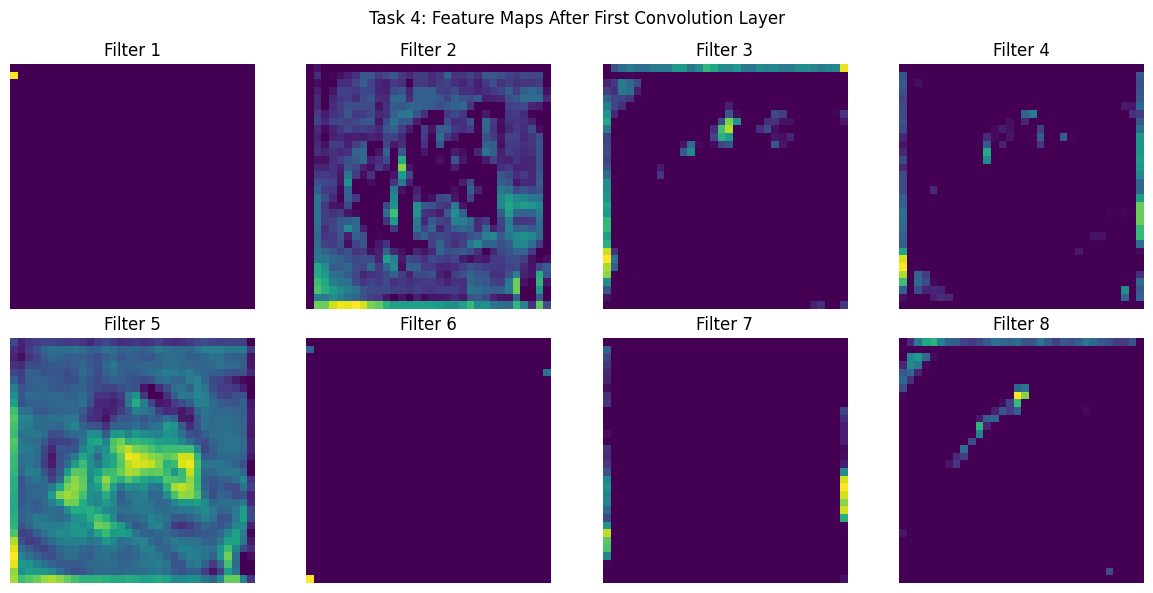

In [9]:
# Build a small model to extract first-conv-layer feature maps
feature_model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(16, (3, 3), activation='relu', padding='same', name='first_conv')
])

feature_maps = feature_model.predict(sample_img, verbose=0)
print("Feature map tensor shape:", feature_maps.shape)  # (1, 32, 32, 16)

plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(feature_maps[0, :, :, i], cmap='viridis')
    plt.title(f"Filter {i+1}")
    plt.axis('off')
plt.suptitle("Task 4: Feature Maps After First Convolution Layer")
plt.tight_layout()
plt.savefig("feature_maps.png", dpi=150)
plt.show()


In [10]:
def build_pooling_cnn(pool_type='max'):
    pool_layer = layers.MaxPooling2D((2, 2)) if pool_type == 'max' else layers.AveragePooling2D((2, 2))
    model = models.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(16, (3, 3), activation='relu', padding='same'),
        pool_layer,
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        pool_layer.__class__((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

pooling_results = {}
for ptype in ['max', 'avg']:
    print(f"\nTraining CNN with {ptype.upper()} Pooling...")
    m = build_pooling_cnn(ptype)
    hist = m.fit(x_train_norm, y_train_cat, epochs=5, batch_size=32,
                 validation_split=0.1, verbose=1)
    test_loss, test_acc = m.evaluate(x_test_norm, y_test_cat, verbose=0)
    pooling_results[ptype] = test_acc
    # show output shape after first pooling layer
    sub_model = models.Model(inputs=m.inputs, outputs=m.layers[1].output)
    print(f"{ptype.upper()} Pooling output shape after first pool:", sub_model.predict(sample_img, verbose=0).shape)

print("\nTest Accuracy Comparison:")
for k, v in pooling_results.items():
    print(f"{k.upper()} Pooling: {v:.4f}")



Training CNN with MAX Pooling...
Epoch 1/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 45s 30ms/step - accuracy: 0.4459 - loss: 1.5414 - val_accuracy: 0.5420 - val_loss: 1.3138
Epoch 2/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 41s 29ms/step - accuracy: 0.5652 - loss: 1.2240 - val_accuracy: 0.5906 - val_loss: 1.1828
Epoch 3/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 42s 30ms/step - accuracy: 0.6181 - loss: 1.0902 - val_accuracy: 0.6170 - val_loss: 1.0960
Epoch 4/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 82s 30ms/step - accuracy: 0.6486 - loss: 1.0065 - val_accuracy: 0.6434 - val_loss: 1.0346
Epoch 5/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 41s 29ms/step - accuracy: 0.6714 - loss: 0.9437 - val_accuracy: 0.6492 - val_loss: 1.0096
MAX Pooling output shape after first pool: (1, 16, 16, 16)

Training CNN with AVG Pooling...
Epoch 1/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 38s 26ms/step - accuracy: 0.4326 - loss: 1.5747 - val_accuracy: 0.5156 - val_loss: 1.3751
Epoch 2/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 36s 26ms/step - accuracy: 0.5490 - loss: 1.265

In [11]:
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(32, (3, 3), padding='same'),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding='same'),
    layers.Activation('relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_13 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,098 (2.08 MB)

 Trainable params: 545,098 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
history = model.fit(
    x_train_norm, y_train_cat,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)


Epoch 1/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 78s 55ms/step - accuracy: 0.5068 - loss: 1.3804 - val_accuracy: 0.6052 - val_loss: 1.1372
Epoch 2/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 83s 55ms/step - accuracy: 0.6469 - loss: 1.0126 - val_accuracy: 0.6558 - val_loss: 0.9936
Epoch 3/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 76s 54ms/step - accuracy: 0.6954 - loss: 0.8750 - val_accuracy: 0.6934 - val_loss: 0.9016
Epoch 4/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 78s 55ms/step - accuracy: 0.7312 - loss: 0.7749 - val_accuracy: 0.7006 - val_loss: 0.8766
Epoch 5/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 76s 54ms/step - accuracy: 0.7607 - loss: 0.6876 - val_accuracy: 0.7060 - val_loss: 0.8771
Epoch 6/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 76s 54ms/step - accuracy: 0.7897 - loss: 0.6109 - val_accuracy: 0.7068 - val_loss: 0.9099
Epoch 7/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 77s 55ms/step - accuracy: 0.8152 - loss: 0.5395 - val_accuracy: 0.7004 - val_loss: 0.9866
Epoch 8/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 80s 53ms/step - accuracy: 0.8341 -

In [13]:
test_loss, test_acc = model.evaluate(x_test_norm, y_test_cat, verbose=0)
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Loss    : {test_loss:.4f}")

y_pred_probs = model.predict(x_test_norm, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = y_test.flatten()

precision = precision_score(y_true, y_pred, average='macro')
recall = recall_score(y_true, y_pred, average='macro')
f1 = f1_score(y_true, y_pred, average='macro')

print(f"\nPrecision (macro): {precision:.4f}")
print(f"Recall    (macro): {recall:.4f}")
print(f"F1-score  (macro): {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))


Test Accuracy: 0.6521
Test Loss    : 2.5372

Precision (macro): 0.6620
Recall    (macro): 0.6521
F1-score  (macro): 0.6526

Classification Report:
              precision    recall  f1-score   support

    airplane       0.63      0.77      0.69      1000
  automobile       0.70      0.86      0.77      1000
        bird       0.61      0.50      0.55      1000
         cat       0.46      0.52      0.49      1000
        deer       0.62      0.53      0.57      1000
         dog       0.49      0.56      0.52      1000
        frog       0.77      0.67      0.72      1000
       horse       0.75      0.70      0.72      1000
        ship       0.78      0.76      0.77      1000
       truck       0.83      0.66      0.73      1000

    accuracy                           0.65     10000
   macro avg       0.66      0.65      0.65     10000
weighted avg       0.66      0.65      0.65     10000



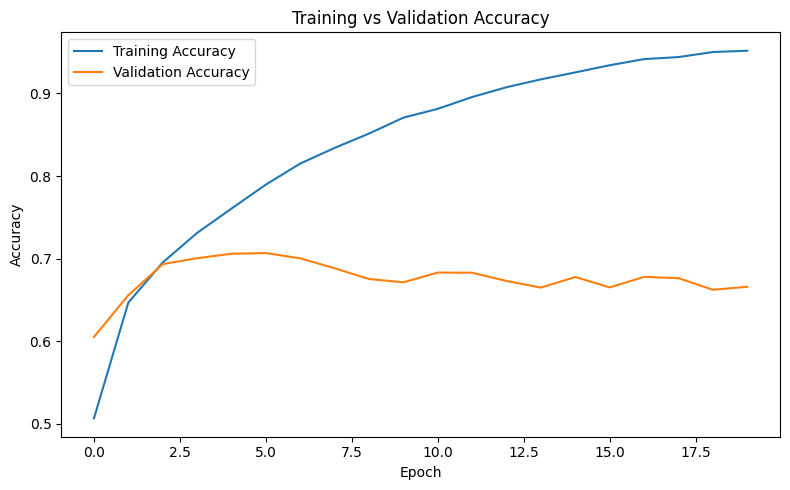

In [14]:
# Training vs Validation Accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig("accuracy_curve.png", dpi=150)
plt.show()


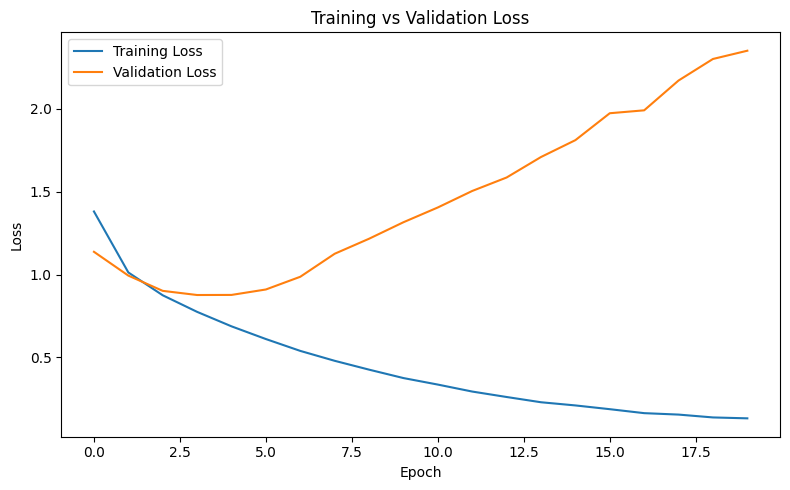

In [15]:
# Training vs Validation Loss
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.tight_layout()
plt.savefig("loss_curve.png", dpi=150)
plt.show()


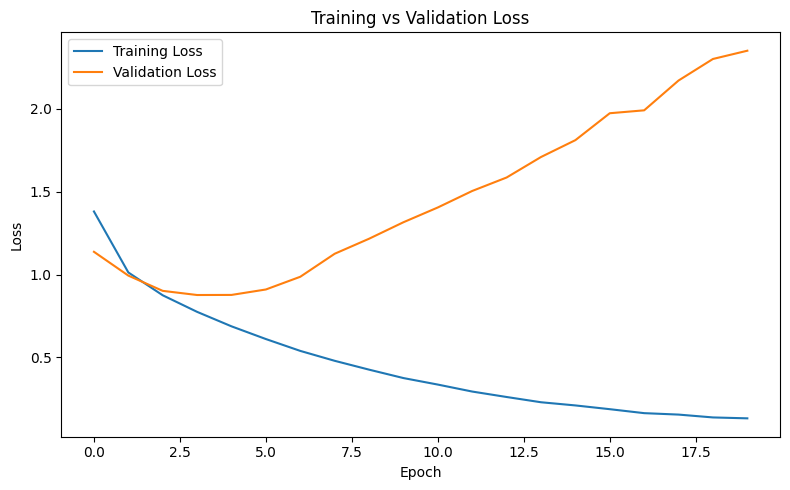

In [16]:
# Training vs Validation Loss
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.tight_layout()
plt.savefig("loss_curve.png", dpi=150)
plt.show()


In [17]:
# 1. Output size for a 64x64 image, 5x5 kernel, stride 2, padding 2
N, F, P, S = 64, 5, 2, 2
out_size = (N - F + 2 * P) // S + 1
print(f"1) Output size (64x64, kernel=5x5, stride=2, padding=2): {out_size} x {out_size}")

# 2. Trainable parameters: 64 filters of size 3x3, RGB input (3 channels)
filters, kernel, channels = 64, 3, 3
params = (kernel * kernel * channels + 1) * filters
print(f"2) Trainable parameters (64 filters, 3x3 kernel, RGB input): {params}")


1) Output size (64x64, kernel=5x5, stride=2, padding=2): 32 x 32
2) Trainable parameters (64 filters, 3x3 kernel, RGB input): 1792


In [18]:
# 4. Replace Max Pooling with Average Pooling in the Task 6 architecture and compare
model_avg = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.AveragePooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.AveragePooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])
model_avg.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history_avg = model_avg.fit(x_train_norm, y_train_cat, epochs=20, batch_size=32,
                             validation_split=0.1, verbose=1)

avg_test_loss, avg_test_acc = model_avg.evaluate(x_test_norm, y_test_cat, verbose=0)
print(f"\nMaxPool CNN Test Accuracy: {test_acc:.4f}")
print(f"AvgPool CNN Test Accuracy: {avg_test_acc:.4f}")


Epoch 1/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 69s 48ms/step - accuracy: 0.4760 - loss: 1.4667 - val_accuracy: 0.5710 - val_loss: 1.2259
Epoch 2/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 67s 47ms/step - accuracy: 0.6059 - loss: 1.1193 - val_accuracy: 0.6324 - val_loss: 1.0583
Epoch 3/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 66s 47ms/step - accuracy: 0.6602 - loss: 0.9682 - val_accuracy: 0.6646 - val_loss: 0.9671
Epoch 4/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 83s 48ms/step - accuracy: 0.7025 - loss: 0.8556 - val_accuracy: 0.6726 - val_loss: 0.9408
Epoch 5/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 67s 47ms/step - accuracy: 0.7373 - loss: 0.7618 - val_accuracy: 0.6790 - val_loss: 0.9281
Epoch 6/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 66s 47ms/step - accuracy: 0.7678 - loss: 0.6765 - val_accuracy: 0.6728 - val_loss: 0.9780
Epoch 7/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 82s 47ms/step - accuracy: 0.7938 - loss: 0.5999 - val_accuracy: 0.6592 - val_loss: 1.0731
Epoch 8/20
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 82s 47ms/step - accuracy: 0.8185 -

In [21]:
# 5. Increase filters from 16 to 64 and analyze effect on accuracy and computation time
import time

def build_filter_cnn(f1):
    m = models.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(f1, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(f1 * 2, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return m

filter_counts = [16, 64]
filter_results = {}
for f in filter_counts:
    m = build_filter_cnn(f)
    start = time.time()
    m.fit(x_train_norm, y_train_cat, epochs=5, batch_size=32, validation_split=0.1, verbose=0)
    elapsed = time.time() - start
    _, acc = m.evaluate(x_test_norm, y_test_cat, verbose=0)
    filter_results[f] = (acc, elapsed)
    print(f"Filters={f:<4} Test Accuracy={acc:.4f}  Training Time={elapsed:.1f}s")


Filters=16   Test Accuracy=0.6493  Training Time=213.6s
Filters=64   Test Accuracy=0.6772  Training Time=941.5s


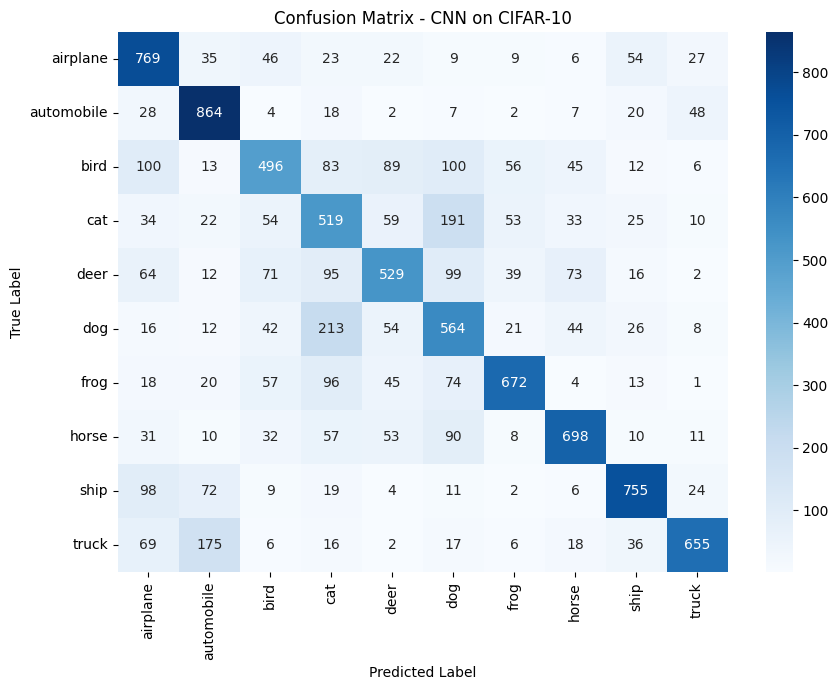

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# class_names should match your CIFAR-10 label order
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# Get predictions (skip this if you already have y_pred / y_true from Task 7)
y_pred_probs = model.predict(x_test_norm, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = y_test.flatten()

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - CNN on CIFAR-10")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)  # for your LaTeX report
plt.show()

In [23]:
# Final (last epoch) training accuracy
final_train_accuracy = history.history['accuracy'][-1]
print(f"Final Training Accuracy: {final_train_accuracy:.4f}")

# Final validation accuracy, for comparison
final_val_accuracy = history.history['val_accuracy'][-1]
print(f"Final Validation Accuracy: {final_val_accuracy:.4f}")

Final Training Accuracy: 0.9517
Final Validation Accuracy: 0.6660


### Task: Zip all generated image files

In [19]:
import zipfile
import os

image_files = [
    'sample_images.png',
    'class_distribution.png',
    'feature_maps.png',
    'accuracy_curve.png',
    'loss_curve.png',
    '/content/Screenshot From 2026-07-30 14-29-38.png'
]

zip_file_name = 'generated_images.zip'

with zipfile.ZipFile(zip_file_name, 'w') as zipf:
    for file in image_files:
        if os.path.exists(file):
            zipf.write(file, os.path.basename(file))
            print(f'Added {file} to {zip_file_name}')
        else:
            print(f'Warning: File not found - {file}')

print(f'Successfully created {zip_file_name}')

Added sample_images.png to generated_images.zip
Added class_distribution.png to generated_images.zip
Added feature_maps.png to generated_images.zip
Added accuracy_curve.png to generated_images.zip
Added loss_curve.png to generated_images.zip
Added /content/Screenshot From 2026-07-30 14-29-38.png to generated_images.zip
Successfully created generated_images.zip


In [20]:
from google.colab import files

files.download('generated_images.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>